# Checkpoint 4 — First XGBoost baseline

**Question.** Can a compact set of composition and path descriptors predict DFT migration barriers for the 71 provisional Li/Na cathode paths better than a training-fold median?

This notebook replaces the earlier broad project exploration. It does not alter source data, download data, tune hyperparameters extensively, or claim to predict conductivity. All validation keeps framework/paper-connected records together.

## 1. Model and validation contract

For path (i), the target is its calculated migration barrier (E_{m,i}) in eV. The input vector contains mobile-ion identity, hop length, nominal mobile-ion number density, and normalized host elemental fractions.

XGBoost represents the prediction as an additive ensemble of regression trees,

\[
\widehat{E}_{m,i}=\sum_{t=1}^{T}\eta f_t(\mathbf{x}_i),
\]

where each tree (f_t) partitions descriptor space using binary rules and assigns a constant value to each terminal leaf. Training minimizes a regularized objective,

\[
\mathcal{L}=\sum_i \left(E_{m,i}-\widehat{E}_{m,i}\right)^2
+\sum_t\left(\gamma L_t+\frac{\lambda}{2}\lVert\mathbf{w}_t\rVert_2^2+\alpha\lVert\mathbf{w}_t\rVert_1\right),
\]

so shallow trees, shrinkage, row/feature subsampling, and leaf penalties limit complexity. The reference model is `DummyRegressor(strategy="median")`, fitted separately inside every training fold.

Primary validation is three-fold cross-validation over the 11 framework/paper connected groups. Leave-one-group-out (LOGO) validation is the sensitivity analysis; no connected group can cross a train/test boundary. Metrics are

\[
\mathrm{MAE}=\frac{1}{n}\sum_i|E_{m,i}-\widehat{E}_{m,i}|,\qquad
\mathrm{RMSE}=\sqrt{\frac{1}{n}\sum_i(E_{m,i}-\widehat{E}_{m,i})^2},
\]

\[
R^2=1-\frac{\sum_i(E_{m,i}-\widehat{E}_{m,i})^2}
{\sum_i(E_{m,i}-\overline{E}_m)^2}.
\]

## 2. Reproducible implementation

The next cell contains the complete data preparation, grouping, modeling, evaluation, and plotting functions. It is collapsed by default for presentation but remains part of the notebook.

In [1]:
"""Checkpoint 4: grouped XGBoost baseline for cathode migration barriers.

The script reads the existing migration-barrier CSV, selects the 71 provisional
cathode paths, constructs the predeclared feature matrix, evaluates a median
DummyRegressor and a conservative XGBoost model, and writes predictions and up
to three figures. Source data are never modified.
"""

from __future__ import annotations

import hashlib
import json
from dataclasses import dataclass, field
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import xgboost
from sklearn.dummy import DummyRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold, LeaveOneGroupOut
from xgboost import XGBRegressor


ROOT = Path.cwd().resolve()
SOURCE = ROOT / "data/processed/cathode_migration_barrier_leads.csv"
OUTPUT_DIR = ROOT / "results/ml"
FIGURE_DIR = OUTPUT_DIR / "figures"
PREDICTION_PATH = OUTPUT_DIR / "checkpoint4_cross_validated_predictions.csv"

RANDOM_SEED = 404
ILLINI_BLUE = "#13294B"
ILLINI_ORANGE = "#FF5F05"
LIGHT_BLUE = "#6FA3CF"
GRAY = "#A5A8AA"

MODEL_CONFIG = {
    "objective": "reg:squarederror",
    "n_estimators": 120,
    "learning_rate": 0.03,
    "max_depth": 2,
    "min_child_weight": 3,
    "subsample": 0.80,
    "colsample_bytree": 0.80,
    "reg_alpha": 0.10,
    "reg_lambda": 5.0,
    "gamma": 0.0,
    "tree_method": "hist",
    "importance_type": "gain",
    "random_state": RANDOM_SEED,
    "n_jobs": 1,
    "verbosity": 0,
}


@dataclass
class UnionFind:
    parent: dict[str, str] = field(default_factory=dict)

    def find(self, node: str) -> str:
        self.parent.setdefault(node, node)
        if self.parent[node] != node:
            self.parent[node] = self.find(self.parent[node])
        return self.parent[node]

    def union(self, left: str, right: str) -> None:
        left_root = self.find(left)
        right_root = self.find(right)
        if left_root != right_root:
            self.parent[right_root] = left_root


def parse_framework_key(value: str) -> dict[str, float]:
    parsed = {}
    for item in value.split("|"):
        element, fraction = item.split(":")
        parsed[element] = float(fraction)
    return parsed


def add_connected_groups(data: pd.DataFrame) -> pd.DataFrame:
    union_find = UnionFind()
    framework_nodes = []
    for row in data.itertuples(index=False):
        if pd.isna(row.source_bibtex_key):
            raise ValueError("Dataset A unexpectedly contains a missing source paper key")
        framework_node = f"F:{row.mobile_ion}|{row.framework_key}"
        paper_node = f"P:{row.source_bibtex_key}"
        union_find.union(framework_node, paper_node)
        framework_nodes.append(framework_node)

    labeled = data.copy()
    labeled["component_root"] = [union_find.find(node) for node in framework_nodes]
    component_rows = []
    for root, group in labeled.groupby("component_root"):
        frameworks = sorted(
            (group["mobile_ion"] + " | " + group["framework_key"]).unique()
        )
        component_rows.append(
            {
                "component_root": root,
                "n_paths": len(group),
                "frameworks": "; ".join(frameworks),
            }
        )
    components = pd.DataFrame(component_rows).sort_values(
        ["n_paths", "frameworks"], ascending=[False, True]
    )
    components["connected_group"] = [
        f"A-C{number:02d}" for number in range(1, len(components) + 1)
    ]
    root_to_id = components.set_index("component_root")["connected_group"]
    labeled["connected_group"] = labeled["component_root"].map(root_to_id)
    return labeled.drop(columns="component_root")


def prepare_dataset() -> tuple[pd.DataFrame, pd.DataFrame, pd.Series, list[str]]:
    source = pd.read_csv(SOURCE)
    data = source.loc[
        source["auxiliary_barrier_training_status"].eq("provisional_cathode_role")
    ].copy()
    if len(data) != 71:
        raise ValueError(f"Expected 71 provisional cathode paths, found {len(data)}")
    if not data["cathode_role_evidence"].eq("title_mentions_cathode").all():
        raise ValueError("Dataset A contains an unexpected cathode-role classification")
    if data["source_record_id"].duplicated().any():
        raise ValueError("source_record_id is not unique")

    data = add_connected_groups(data).reset_index(drop=True)
    if data["connected_group"].nunique() != 11:
        raise ValueError("Expected 11 connected groups")

    parsed = data["framework_key"].map(parse_framework_key)
    elements = sorted({element for composition in parsed for element in composition})
    if len(elements) != 14:
        raise ValueError(f"Expected 14 Dataset A host elements, found {len(elements)}")

    features = pd.DataFrame(index=data.index)
    features["mobile_ion_Na"] = data["mobile_ion"].eq("Na").astype(float)
    features["hop_length_A"] = data["hop_length_A"].astype(float)
    features["mobile_ion_density_1e22_cm3"] = (
        data["mobile_ion_number_density_cm3"].astype(float) / 1.0e22
    )
    for element in elements:
        features[f"host_fraction_{element}"] = parsed.map(
            lambda composition, symbol=element: composition.get(symbol, 0.0)
        )

    target = data["migration_barrier_eV"].astype(float)
    if features.isna().any().any() or target.isna().any():
        raise ValueError("Prepared model data contain missing values")
    if not np.isfinite(features.to_numpy()).all() or not np.isfinite(target).all():
        raise ValueError("Prepared model data contain non-finite values")
    return data, features, target, features.columns.tolist()


def make_xgboost() -> XGBRegressor:
    return XGBRegressor(**MODEL_CONFIG)


def metric_row(actual: np.ndarray, predicted: np.ndarray) -> dict[str, float]:
    result = {
        "mae_eV": float(mean_absolute_error(actual, predicted)),
        "rmse_eV": float(np.sqrt(mean_squared_error(actual, predicted))),
        "r2": np.nan,
    }
    if len(actual) >= 2 and not np.isclose(np.var(actual), 0.0):
        result["r2"] = float(r2_score(actual, predicted))
    return result


def evaluate_three_fold(
    data: pd.DataFrame,
    features: pd.DataFrame,
    target: pd.Series,
) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    splitter = GroupKFold(n_splits=3)
    groups = data["connected_group"]
    predictions = pd.DataFrame(index=data.index)
    fold_rows = []
    importance_rows = []

    for fold_number, (train_index, test_index) in enumerate(
        splitter.split(features, target, groups), start=1
    ):
        train_groups = set(groups.iloc[train_index])
        test_groups = set(groups.iloc[test_index])
        if train_groups.intersection(test_groups):
            raise RuntimeError("Connected-group leakage detected in three-fold CV")

        x_train = features.iloc[train_index]
        x_test = features.iloc[test_index]
        y_train = target.iloc[train_index]
        y_test = target.iloc[test_index]

        model = make_xgboost()
        dummy = DummyRegressor(strategy="median")
        model.fit(x_train, y_train)
        dummy.fit(x_train, y_train)
        xgb_prediction = model.predict(x_test)
        dummy_prediction = dummy.predict(x_test)

        predictions.loc[test_index, "threefold_fold"] = fold_number
        predictions.loc[test_index, "xgb_pred_3fold_eV"] = xgb_prediction
        predictions.loc[test_index, "dummy_pred_3fold_eV"] = dummy_prediction

        xgb_metrics = metric_row(y_test.to_numpy(), xgb_prediction)
        dummy_metrics = metric_row(y_test.to_numpy(), dummy_prediction)
        fold_rows.append(
            {
                "fold": fold_number,
                "n_train": len(train_index),
                "n_test": len(test_index),
                "n_train_groups": len(train_groups),
                "n_test_groups": len(test_groups),
                "test_groups": ";".join(sorted(test_groups)),
                "test_Li": int(data.iloc[test_index]["mobile_ion"].eq("Li").sum()),
                "test_Na": int(data.iloc[test_index]["mobile_ion"].eq("Na").sum()),
                **{f"xgb_{key}": value for key, value in xgb_metrics.items()},
                **{f"dummy_{key}": value for key, value in dummy_metrics.items()},
            }
        )

        permutation = permutation_importance(
            model,
            x_test,
            y_test,
            scoring="neg_mean_absolute_error",
            n_repeats=30,
            random_state=RANDOM_SEED + fold_number,
            n_jobs=1,
        )
        for feature, mean_importance, repeat_std in zip(
            features.columns,
            permutation.importances_mean,
            permutation.importances_std,
        ):
            importance_rows.append(
                {
                    "fold": fold_number,
                    "n_test": len(test_index),
                    "feature": feature,
                    "increase_in_mae_eV": float(mean_importance),
                    "repeat_std_eV": float(repeat_std),
                }
            )

    required = ["xgb_pred_3fold_eV", "dummy_pred_3fold_eV", "threefold_fold"]
    if predictions[required].isna().any().any():
        raise RuntimeError("Three-fold CV did not predict every row exactly once")
    return predictions, pd.DataFrame(fold_rows), pd.DataFrame(importance_rows)


def evaluate_logo(
    data: pd.DataFrame,
    features: pd.DataFrame,
    target: pd.Series,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    splitter = LeaveOneGroupOut()
    groups = data["connected_group"]
    predictions = pd.DataFrame(index=data.index)
    fold_rows = []

    for train_index, test_index in splitter.split(features, target, groups):
        test_group_values = sorted(groups.iloc[test_index].unique())
        if len(test_group_values) != 1:
            raise RuntimeError("LOGO fold contains more than one connected group")
        test_group = test_group_values[0]
        if test_group in set(groups.iloc[train_index]):
            raise RuntimeError("Connected-group leakage detected in LOGO")

        model = make_xgboost()
        dummy = DummyRegressor(strategy="median")
        model.fit(features.iloc[train_index], target.iloc[train_index])
        dummy.fit(features.iloc[train_index], target.iloc[train_index])
        xgb_prediction = model.predict(features.iloc[test_index])
        dummy_prediction = dummy.predict(features.iloc[test_index])

        predictions.loc[test_index, "xgb_pred_logo_eV"] = xgb_prediction
        predictions.loc[test_index, "dummy_pred_logo_eV"] = dummy_prediction
        xgb_metrics = metric_row(target.iloc[test_index].to_numpy(), xgb_prediction)
        dummy_metrics = metric_row(target.iloc[test_index].to_numpy(), dummy_prediction)
        fold_rows.append(
            {
                "held_out_group": test_group,
                "n_train": len(train_index),
                "n_test": len(test_index),
                "test_Li": int(data.iloc[test_index]["mobile_ion"].eq("Li").sum()),
                "test_Na": int(data.iloc[test_index]["mobile_ion"].eq("Na").sum()),
                **{f"xgb_{key}": value for key, value in xgb_metrics.items()},
                **{f"dummy_{key}": value for key, value in dummy_metrics.items()},
            }
        )

    required = ["xgb_pred_logo_eV", "dummy_pred_logo_eV"]
    if predictions[required].isna().any().any():
        raise RuntimeError("LOGO did not predict every row exactly once")
    return predictions, pd.DataFrame(fold_rows).sort_values("held_out_group")


def aggregate_importance(importance_rows: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for feature, group in importance_rows.groupby("feature"):
        weights = group["n_test"].to_numpy(dtype=float)
        values = group["increase_in_mae_eV"].to_numpy(dtype=float)
        weighted_mean = float(np.average(values, weights=weights))
        weighted_std = float(
            np.sqrt(np.average((values - weighted_mean) ** 2, weights=weights))
        )
        rows.append(
            {
                "feature": feature,
                "weighted_mean_increase_in_mae_eV": weighted_mean,
                "across_fold_std_eV": weighted_std,
            }
        )
    return pd.DataFrame(rows).sort_values(
        "weighted_mean_increase_in_mae_eV", ascending=False
    )


def summarize_subsets(predictions: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    ion_rows = []
    for ion, group in predictions.groupby("mobile_ion"):
        for model in ["xgb", "dummy"]:
            actual = group["actual_barrier_eV"].to_numpy()
            predicted = group[f"{model}_pred_3fold_eV"].to_numpy()
            ion_rows.append(
                {
                    "mobile_ion": ion,
                    "model": model,
                    "n": len(group),
                    **metric_row(actual, predicted),
                    "mean_residual_pred_minus_actual_eV": float(
                        np.mean(predicted - actual)
                    ),
                }
            )

    group_rows = []
    for connected_group, group in predictions.groupby("connected_group"):
        actual = group["actual_barrier_eV"].to_numpy()
        xgb_prediction = group["xgb_pred_3fold_eV"].to_numpy()
        dummy_prediction = group["dummy_pred_3fold_eV"].to_numpy()
        group_rows.append(
            {
                "connected_group": connected_group,
                "n": len(group),
                "ions": ",".join(sorted(group["mobile_ion"].unique())),
                "actual_mean_eV": float(np.mean(actual)),
                "xgb_mae_eV": float(mean_absolute_error(actual, xgb_prediction)),
                "dummy_mae_eV": float(mean_absolute_error(actual, dummy_prediction)),
                "xgb_mean_residual_eV": float(np.mean(xgb_prediction - actual)),
            }
        )
    return pd.DataFrame(ion_rows), pd.DataFrame(group_rows).sort_values(
        "xgb_mae_eV", ascending=False
    )


def style_axis(axis: plt.Axes) -> None:
    axis.spines[["top", "right"]].set_visible(False)
    axis.tick_params(colors=ILLINI_BLUE)
    axis.xaxis.label.set_color(ILLINI_BLUE)
    axis.yaxis.label.set_color(ILLINI_BLUE)
    axis.title.set_color(ILLINI_BLUE)


def plot_actual_vs_predicted(predictions: pd.DataFrame) -> None:
    figure, axis = plt.subplots(figsize=(6.8, 5.6), layout="constrained")
    colors = {"Li": ILLINI_BLUE, "Na": ILLINI_ORANGE}
    for ion, group in predictions.groupby("mobile_ion"):
        axis.scatter(
            group["actual_barrier_eV"],
            group["xgb_pred_3fold_eV"],
            s=48,
            alpha=0.78,
            color=colors[ion],
            label=f"XGBoost {ion} (n={len(group)})",
            edgecolor="white",
            linewidth=0.5,
        )
    axis.scatter(
        predictions["actual_barrier_eV"],
        predictions["dummy_pred_3fold_eV"],
        s=28,
        alpha=0.38,
        color=GRAY,
        marker="x",
        label="Fold-median dummy",
    )
    dominant = predictions["connected_group"].eq("A-C01")
    axis.scatter(
        predictions.loc[dominant, "actual_barrier_eV"],
        predictions.loc[dominant, "xgb_pred_3fold_eV"],
        s=95,
        facecolor="none",
        edgecolor="black",
        linewidth=0.8,
        label="A-C01 outline",
    )
    lower = min(predictions["actual_barrier_eV"].min(), predictions["xgb_pred_3fold_eV"].min())
    upper = max(predictions["actual_barrier_eV"].max(), predictions["xgb_pred_3fold_eV"].max())
    padding = 0.06 * (upper - lower)
    axis.plot(
        [lower - padding, upper + padding],
        [lower - padding, upper + padding],
        linestyle="--",
        linewidth=1.2,
        color=GRAY,
    )
    axis.set(
        xlabel="Calculated migration barrier (eV)",
        ylabel="Cross-validated prediction (eV)",
        title="Three-fold connected-group validation",
    )
    axis.legend(frameon=False, fontsize=8, loc="upper left")
    style_axis(axis)
    figure.savefig(
        FIGURE_DIR / "01_cross_validated_predicted_vs_actual.png",
        dpi=220,
        bbox_inches="tight",
    )
    plt.close(figure)


def plot_residuals(predictions: pd.DataFrame) -> None:
    xgb_residual = predictions["xgb_pred_3fold_eV"] - predictions["actual_barrier_eV"]
    dummy_residual = predictions["dummy_pred_3fold_eV"] - predictions["actual_barrier_eV"]
    bins = np.linspace(
        min(xgb_residual.min(), dummy_residual.min()) - 0.05,
        max(xgb_residual.max(), dummy_residual.max()) + 0.05,
        18,
    )

    figure, axes = plt.subplots(1, 2, figsize=(10.8, 4.2), layout="constrained")
    axes[0].hist(
        dummy_residual,
        bins=bins,
        color=GRAY,
        alpha=0.55,
        label="Dummy",
    )
    axes[0].hist(
        xgb_residual,
        bins=bins,
        color=ILLINI_BLUE,
        alpha=0.72,
        label="XGBoost",
    )
    axes[0].axvline(0, color=ILLINI_ORANGE, linewidth=1.8)
    axes[0].set(
        xlabel="Residual: prediction − calculation (eV)",
        ylabel="Paths",
        title="All three-fold predictions",
    )
    axes[0].legend(frameon=False)

    arrays = [
        xgb_residual[predictions["mobile_ion"].eq("Li")],
        xgb_residual[predictions["mobile_ion"].eq("Na")],
    ]
    boxes = axes[1].boxplot(
        arrays,
        tick_labels=["Li", "Na"],
        patch_artist=True,
        showmeans=True,
        meanprops={
            "marker": "D",
            "markerfacecolor": "white",
            "markeredgecolor": ILLINI_ORANGE,
        },
        medianprops={"color": "white", "linewidth": 2},
    )
    for patch, color in zip(boxes["boxes"], [ILLINI_BLUE, ILLINI_ORANGE]):
        patch.set_facecolor(color)
        patch.set_alpha(0.78)
    axes[1].axhline(0, color=GRAY, linewidth=1.3, linestyle="--")
    axes[1].set(
        xlabel="Mobile ion",
        ylabel="XGBoost residual (eV)",
        title="Residuals by ion",
    )
    for axis in axes:
        style_axis(axis)
    figure.suptitle(
        "Residual distributions",
        color=ILLINI_BLUE,
        fontsize=14,
        fontweight="bold",
    )
    figure.savefig(
        FIGURE_DIR / "02_residual_distribution.png",
        dpi=220,
        bbox_inches="tight",
    )
    plt.close(figure)


def plot_importance(importance: pd.DataFrame) -> None:
    selected = importance.head(12).sort_values(
        "weighted_mean_increase_in_mae_eV", ascending=True
    )
    labels = [
        label.replace("host_fraction_", "host fraction ")
        .replace("mobile_ion_density_1e22_cm3", "nominal ion density")
        .replace("mobile_ion_Na", "mobile ion = Na")
        .replace("hop_length_A", "hop length")
        .replace("_", " ")
        for label in selected["feature"]
    ]
    colors = [
        ILLINI_ORANGE if value > 0 else GRAY
        for value in selected["weighted_mean_increase_in_mae_eV"]
    ]

    figure, axis = plt.subplots(figsize=(8.0, 5.3), layout="constrained")
    axis.barh(
        labels,
        selected["weighted_mean_increase_in_mae_eV"],
        xerr=selected["across_fold_std_eV"],
        color=colors,
        alpha=0.88,
        error_kw={"ecolor": ILLINI_BLUE, "elinewidth": 1, "capsize": 2},
    )
    axis.axvline(0, color=ILLINI_BLUE, linewidth=1)
    axis.set(
        xlabel="Validation MAE increase when permuted (eV)",
        ylabel="Feature",
        title="Three-fold permutation importance",
    )
    style_axis(axis)
    figure.savefig(
        FIGURE_DIR / "03_permutation_importance.png",
        dpi=220,
        bbox_inches="tight",
    )
    plt.close(figure)


def print_metrics(
    predictions: pd.DataFrame,
    fold_metrics: pd.DataFrame,
    logo_metrics: pd.DataFrame,
    importance: pd.DataFrame,
) -> None:
    print("Source SHA256:", hashlib.sha256(SOURCE.read_bytes()).hexdigest())
    print("Package versions:", {"xgboost": xgboost.__version__, "sklearn": sklearn.__version__})
    print("Model configuration:")
    print(json.dumps(MODEL_CONFIG, indent=2, sort_keys=True))
    print("\nThree-fold aggregate")
    for model in ["xgb", "dummy"]:
        print(
            model,
            metric_row(
                predictions["actual_barrier_eV"].to_numpy(),
                predictions[f"{model}_pred_3fold_eV"].to_numpy(),
            ),
        )
    print("\nThree-fold metrics")
    print(fold_metrics.to_string(index=False))
    print("\nLOGO aggregate")
    for model in ["xgb", "dummy"]:
        print(
            model,
            metric_row(
                predictions["actual_barrier_eV"].to_numpy(),
                predictions[f"{model}_pred_logo_eV"].to_numpy(),
            ),
        )
    print("\nLOGO metrics")
    print(logo_metrics.to_string(index=False))

    ion_metrics, group_metrics = summarize_subsets(predictions)
    print("\nThree-fold metrics by ion")
    print(ion_metrics.to_string(index=False))
    print("\nThree-fold metrics by connected group")
    print(group_metrics.to_string(index=False))

    dominant = predictions["connected_group"].eq("A-C01")
    print("\nDominant-group influence")
    for label, mask in [("A-C01", dominant), ("without_A-C01", ~dominant)]:
        actual = predictions.loc[mask, "actual_barrier_eV"].to_numpy()
        print(label, "n=", int(mask.sum()))
        for model in ["xgb", "dummy"]:
            predicted = predictions.loc[mask, f"{model}_pred_3fold_eV"].to_numpy()
            print(model, metric_row(actual, predicted))
    print("\nPermutation importance")
    print(importance.to_string(index=False))


def main() -> None:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    FIGURE_DIR.mkdir(parents=True, exist_ok=True)
    data, features, target, feature_names = prepare_dataset()
    print(
        f"Prepared {len(data)} records, {len(feature_names)} features, "
        f"{int(features.isna().sum().sum())} missing feature values, "
        f"{data.connected_group.nunique()} connected groups"
    )
    print("Features:", feature_names)

    threefold_predictions, fold_metrics, importance_rows = evaluate_three_fold(
        data, features, target
    )
    logo_predictions, logo_metrics = evaluate_logo(data, features, target)

    predictions = data[
        [
            "source_record_id",
            "mobile_ion",
            "material_formula",
            "framework_key",
            "crystal_class",
            "source_title",
            "source_bibtex_key",
            "source_dataset_doi",
            "connected_group",
            "hop_length_A",
            "mobile_ion_number_density_cm3",
            "migration_barrier_eV",
        ]
    ].copy()
    predictions = predictions.rename(
        columns={"migration_barrier_eV": "actual_barrier_eV"}
    )
    predictions = predictions.join(threefold_predictions).join(logo_predictions)
    predictions["xgb_residual_3fold_eV"] = (
        predictions["xgb_pred_3fold_eV"] - predictions["actual_barrier_eV"]
    )
    predictions["dummy_residual_3fold_eV"] = (
        predictions["dummy_pred_3fold_eV"] - predictions["actual_barrier_eV"]
    )
    predictions["xgb_residual_logo_eV"] = (
        predictions["xgb_pred_logo_eV"] - predictions["actual_barrier_eV"]
    )
    predictions["dummy_residual_logo_eV"] = (
        predictions["dummy_pred_logo_eV"] - predictions["actual_barrier_eV"]
    )
    predictions["checkpoint2_high_barrier_review"] = predictions[
        "actual_barrier_eV"
    ].gt(1.604375)
    predictions.to_csv(PREDICTION_PATH, index=False, float_format="%.8g")

    importance = aggregate_importance(importance_rows)
    plot_actual_vs_predicted(predictions)
    plot_residuals(predictions)
    plot_importance(importance)
    print_metrics(predictions, fold_metrics, logo_metrics, importance)
    print(f"\nSaved predictions to {PREDICTION_PATH.relative_to(ROOT)}")
    print(f"Saved three figures to {FIGURE_DIR.relative_to(ROOT)}")

Matplotlib is building the font cache; this may take a moment.


In [2]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

data, features, target, feature_names = prepare_dataset()

audit = pd.Series({
    "source file": str(SOURCE.relative_to(ROOT)),
    "source SHA256": hashlib.sha256(SOURCE.read_bytes()).hexdigest(),
    "usable paths": len(data),
    "Li paths": int(data["mobile_ion"].eq("Li").sum()),
    "Na paths": int(data["mobile_ion"].eq("Na").sum()),
    "connected groups": data["connected_group"].nunique(),
    "features": len(feature_names),
    "missing feature values": int(features.isna().sum().sum()),
    "missing targets": int(target.isna().sum()),
    "XGBoost version": xgboost.__version__,
    "scikit-learn version": sklearn.__version__,
})
display(audit.to_frame("value"))

feature_table = pd.DataFrame({
    "model feature": feature_names,
    "valid records": features.notna().sum().to_numpy(),
})
display(feature_table)

,value
source file,data/processed/cathode_migration_barrier_leads...
source SHA256,e36fb44a4d05d2d3da14d4553a8503c916367ca016fa95...
usable paths,71
Li paths,38
Na paths,33
connected groups,11
features,17
missing feature values,0
missing targets,0
XGBoost version,3.4.1


,model feature,valid records
0,mobile_ion_Na,71
1,hop_length_A,71
2,mobile_ion_density_1e22_cm3,71
3,host_fraction_Al,71
4,host_fraction_B,71
5,host_fraction_C,71
6,host_fraction_Co,71
7,host_fraction_Cr,71
8,host_fraction_F,71
9,host_fraction_Fe,71


All 71 provisional cathode paths are retained, including the high-barrier record identified in Checkpoint 2. Identifiers, source fields, evidence labels, review flags, and opaque formula/framework strings are retained only as provenance and grouping metadata—not model inputs.

In [3]:
threefold_predictions, fold_metrics, importance_rows = evaluate_three_fold(
    data, features, target
)
logo_predictions, logo_metrics = evaluate_logo(data, features, target)

predictions = data[[
    "source_record_id", "mobile_ion", "material_formula", "framework_key",
    "crystal_class", "source_title", "source_bibtex_key", "source_dataset_doi",
    "connected_group", "hop_length_A", "mobile_ion_number_density_cm3",
    "migration_barrier_eV",
]].copy().rename(columns={"migration_barrier_eV": "actual_barrier_eV"})
predictions = predictions.join(threefold_predictions).join(logo_predictions)

for scheme in ["3fold", "logo"]:
    predictions[f"xgb_residual_{scheme}_eV"] = (
        predictions[f"xgb_pred_{scheme}_eV"] - predictions["actual_barrier_eV"]
    )
    predictions[f"dummy_residual_{scheme}_eV"] = (
        predictions[f"dummy_pred_{scheme}_eV"] - predictions["actual_barrier_eV"]
    )

predictions["checkpoint2_high_barrier_review"] = predictions[
    "actual_barrier_eV"
].gt(1.604375)
predictions.to_csv(PREDICTION_PATH, index=False, float_format="%.8g")

importance = aggregate_importance(importance_rows)
ion_metrics, group_metrics = summarize_subsets(predictions)

def aggregate_metrics(scheme):
    rows = []
    for model in ["XGBoost", "Dummy median"]:
        prefix = "xgb" if model == "XGBoost" else "dummy"
        row = metric_row(
            predictions["actual_barrier_eV"].to_numpy(),
            predictions[f"{prefix}_pred_{scheme}_eV"].to_numpy(),
        )
        rows.append({"model": model, **row})
    return pd.DataFrame(rows).set_index("model")

display(pd.Series(MODEL_CONFIG, name="value").to_frame())

,value
objective,reg:squarederror
n_estimators,120
learning_rate,0.03
max_depth,2
min_child_weight,3
subsample,0.8
colsample_bytree,0.8
reg_alpha,0.1
reg_lambda,5.0
gamma,0.0


## 3. Grouped cross-validation results

In [4]:
primary_metrics = aggregate_metrics("3fold")
logo_aggregate = aggregate_metrics("logo")

print("Primary: pooled out-of-fold metrics from three grouped folds")
display(primary_metrics.style.format({"mae_eV": "{:.3f}", "rmse_eV": "{:.3f}", "r2": "{:.3f}"}))

fold_display = fold_metrics[[
    "fold", "n_train", "n_test", "n_train_groups", "n_test_groups", "test_groups",
    "xgb_mae_eV", "xgb_rmse_eV", "xgb_r2",
    "dummy_mae_eV", "dummy_rmse_eV", "dummy_r2",
]].copy()
display(fold_display.style.format({
    "xgb_mae_eV": "{:.3f}", "xgb_rmse_eV": "{:.3f}", "xgb_r2": "{:.3f}",
    "dummy_mae_eV": "{:.3f}", "dummy_rmse_eV": "{:.3f}", "dummy_r2": "{:.3f}",
}))

mae_gain = primary_metrics.loc["Dummy median", "mae_eV"] - primary_metrics.loc["XGBoost", "mae_eV"]
print(f"Path-weighted three-fold MAE improvement: {mae_gain:.4f} eV "
      f"({100 * mae_gain / primary_metrics.loc['Dummy median', 'mae_eV']:.2f}%).")

Primary: pooled out-of-fold metrics from three grouped folds


,mae_eV,rmse_eV,r2
model,,,
XGBoost,0.273,0.392,-0.062
Dummy median,0.275,0.399,-0.105


,fold,n_train,n_test,n_train_groups,n_test_groups,test_groups,xgb_mae_eV,xgb_rmse_eV,xgb_r2,dummy_mae_eV,dummy_rmse_eV,dummy_r2
0,1,39,32,10,1,A-C01,0.313,0.487,-0.050,0.334,0.509,-0.146
1,2,51,20,6,5,A-C02;A-C04;A-C09;A-C10;A-C11,0.237,0.291,-0.529,0.217,0.248,-0.110
2,3,52,19,6,5,A-C03;A-C05;A-C06;A-C07;A-C08,0.242,0.290,-0.057,0.236,0.308,-0.196


Path-weighted three-fold MAE improvement: 0.0022 eV (0.79%).


In [5]:
print("Sensitivity: pooled leave-one-connected-group-out metrics")
display(logo_aggregate.style.format({"mae_eV": "{:.3f}", "rmse_eV": "{:.3f}", "r2": "{:.3f}"}))

logo_display = logo_metrics[[
    "held_out_group", "n_test", "test_Li", "test_Na",
    "xgb_mae_eV", "xgb_rmse_eV", "xgb_r2",
    "dummy_mae_eV", "dummy_rmse_eV", "dummy_r2",
]].copy()
display(logo_display.style.format({
    "xgb_mae_eV": "{:.3f}", "xgb_rmse_eV": "{:.3f}", "xgb_r2": "{:.3f}",
    "dummy_mae_eV": "{:.3f}", "dummy_rmse_eV": "{:.3f}", "dummy_r2": "{:.3f}",
}, na_rep="n.a."))

Sensitivity: pooled leave-one-connected-group-out metrics


,mae_eV,rmse_eV,r2
model,,,
XGBoost,0.278,0.399,-0.103
Dummy median,0.273,0.398,-0.095


,held_out_group,n_test,test_Li,test_Na,xgb_mae_eV,xgb_rmse_eV,xgb_r2,dummy_mae_eV,dummy_rmse_eV,dummy_r2
0,A-C01,32,18,14,0.313,0.487,-0.050,0.334,0.509,-0.146
1,A-C02,10,10,0,0.191,0.256,-0.071,0.184,0.248,-0.000
2,A-C03,6,6,0,0.373,0.432,-21.383,0.124,0.154,-1.850
3,A-C04,5,0,5,0.185,0.217,-0.260,0.175,0.202,-0.089
4,A-C05,5,0,5,0.064,0.074,-0.714,0.233,0.239,-16.767
5,A-C06,3,3,0,0.319,0.350,-0.213,0.333,0.355,-0.247
6,A-C07,3,0,3,0.398,0.401,0.435,0.462,0.548,-0.054
7,A-C08,2,0,2,0.229,0.233,-38.574,0.218,0.221,-34.714
8,A-C09,2,0,2,0.392,0.452,-126.769,0.230,0.233,-33.063
9,A-C10,2,0,2,0.361,0.363,-81.412,0.280,0.283,-49.000


The three-fold result is only a marginal path-weighted improvement over the median reference, and both models have negative pooled (R^2). Under the stricter LOGO sensitivity analysis, XGBoost is slightly worse than the dummy model. Very negative fold-level (R^2) values for tiny, low-variance groups are unstable; MAE and RMSE are more interpretable there.

## 4. Error and influence diagnostics

In [6]:
print("Three-fold metrics by mobile ion")
display(ion_metrics.style.format({
    "mae_eV": "{:.3f}", "rmse_eV": "{:.3f}", "r2": "{:.3f}",
    "mean_residual_pred_minus_actual_eV": "{:+.3f}",
}))

dominant = predictions["connected_group"].eq("A-C01")
influence_rows = []
for subset, mask in [("A-C01", dominant), ("All other groups", ~dominant)]:
    for model, prefix in [("XGBoost", "xgb"), ("Dummy median", "dummy")]:
        row = metric_row(
            predictions.loc[mask, "actual_barrier_eV"].to_numpy(),
            predictions.loc[mask, f"{prefix}_pred_3fold_eV"].to_numpy(),
        )
        influence_rows.append({"subset": subset, "model": model, "n": int(mask.sum()), **row})
display(pd.DataFrame(influence_rows).style.format({
    "mae_eV": "{:.3f}", "rmse_eV": "{:.3f}", "r2": "{:.3f}",
}))

print("Largest absolute three-fold XGBoost errors (retained, not removed)")
largest_errors = predictions.assign(
    absolute_error_eV=predictions["xgb_residual_3fold_eV"].abs()
).nlargest(8, "absolute_error_eV")[[
    "source_record_id", "mobile_ion", "connected_group", "actual_barrier_eV",
    "xgb_pred_3fold_eV", "xgb_residual_3fold_eV", "absolute_error_eV",
    "checkpoint2_high_barrier_review",
]]
display(largest_errors.style.format({
    "actual_barrier_eV": "{:.3f}", "xgb_pred_3fold_eV": "{:.3f}",
    "xgb_residual_3fold_eV": "{:+.3f}", "absolute_error_eV": "{:.3f}",
}))

Three-fold metrics by mobile ion


,mobile_ion,model,n,mae_eV,rmse_eV,r2,mean_residual_pred_minus_actual_eV
0,Li,xgb,38,0.235,0.297,-0.352,+0.017
1,Li,dummy,38,0.208,0.256,-0.001,+0.001
2,Na,xgb,33,0.315,0.478,-0.066,-0.130
3,Na,dummy,33,0.352,0.518,-0.252,-0.202


,subset,model,n,mae_eV,rmse_eV,r2
0,A-C01,XGBoost,32,0.313,0.487,-0.050
1,A-C01,Dummy median,32,0.334,0.509,-0.146
2,All other groups,XGBoost,39,0.240,0.290,-0.206
3,All other groups,Dummy median,39,0.226,0.279,-0.114


Largest absolute three-fold XGBoost errors (retained, not removed)


,source_record_id,mobile_ion,connected_group,actual_barrier_eV,xgb_pred_3fold_eV,xgb_residual_3fold_eV,absolute_error_eV,checkpoint2_high_barrier_review
55,Devi2025:476,Na,A-C01,2.308,0.558,-1.750,1.750,True
16,Devi2025:153,Na,A-C01,1.547,0.437,-1.110,1.110,False
2,Devi2025:18,Na,A-C01,1.431,0.586,-0.845,0.845,False
59,Devi2025:485,Na,A-C01,1.409,0.586,-0.823,0.823,False
58,Devi2025:484,Li,A-C01,1.199,0.445,-0.754,0.754,False
20,Devi2025:205,Na,A-C01,1.039,0.405,-0.634,0.634,False
67,Devi2025:580,Li,A-C02,0.980,0.385,-0.595,0.595,False
70,Devi2025:618,Li,A-C03,0.437,1.029,+0.592,0.592,False


In [7]:
display(importance.head(12).style.format({
    "weighted_mean_increase_in_mae_eV": "{:+.4f}",
    "across_fold_std_eV": "{:.4f}",
}))

,feature,weighted_mean_increase_in_mae_eV,across_fold_std_eV
0,hop_length_A,+0.0313,0.0179
10,host_fraction_O,+0.0008,0.0036
11,host_fraction_P,+0.0007,0.0006
8,host_fraction_Mn,+0.0001,0.0002
4,host_fraction_Co,+0.0000,0.0000
5,host_fraction_Cr,+0.0000,0.0000
1,host_fraction_Al,+0.0000,0.0000
9,host_fraction_Ni,+0.0000,0.0000
3,host_fraction_C,+0.0000,0.0000
2,host_fraction_B,+0.0000,0.0000


Only hop length has a consistently positive permutation signal. The remaining composition, ion-identity, and nominal-density effects are near zero or unstable across folds. This is predictive association under this split—not evidence that hop length alone causes the barrier.

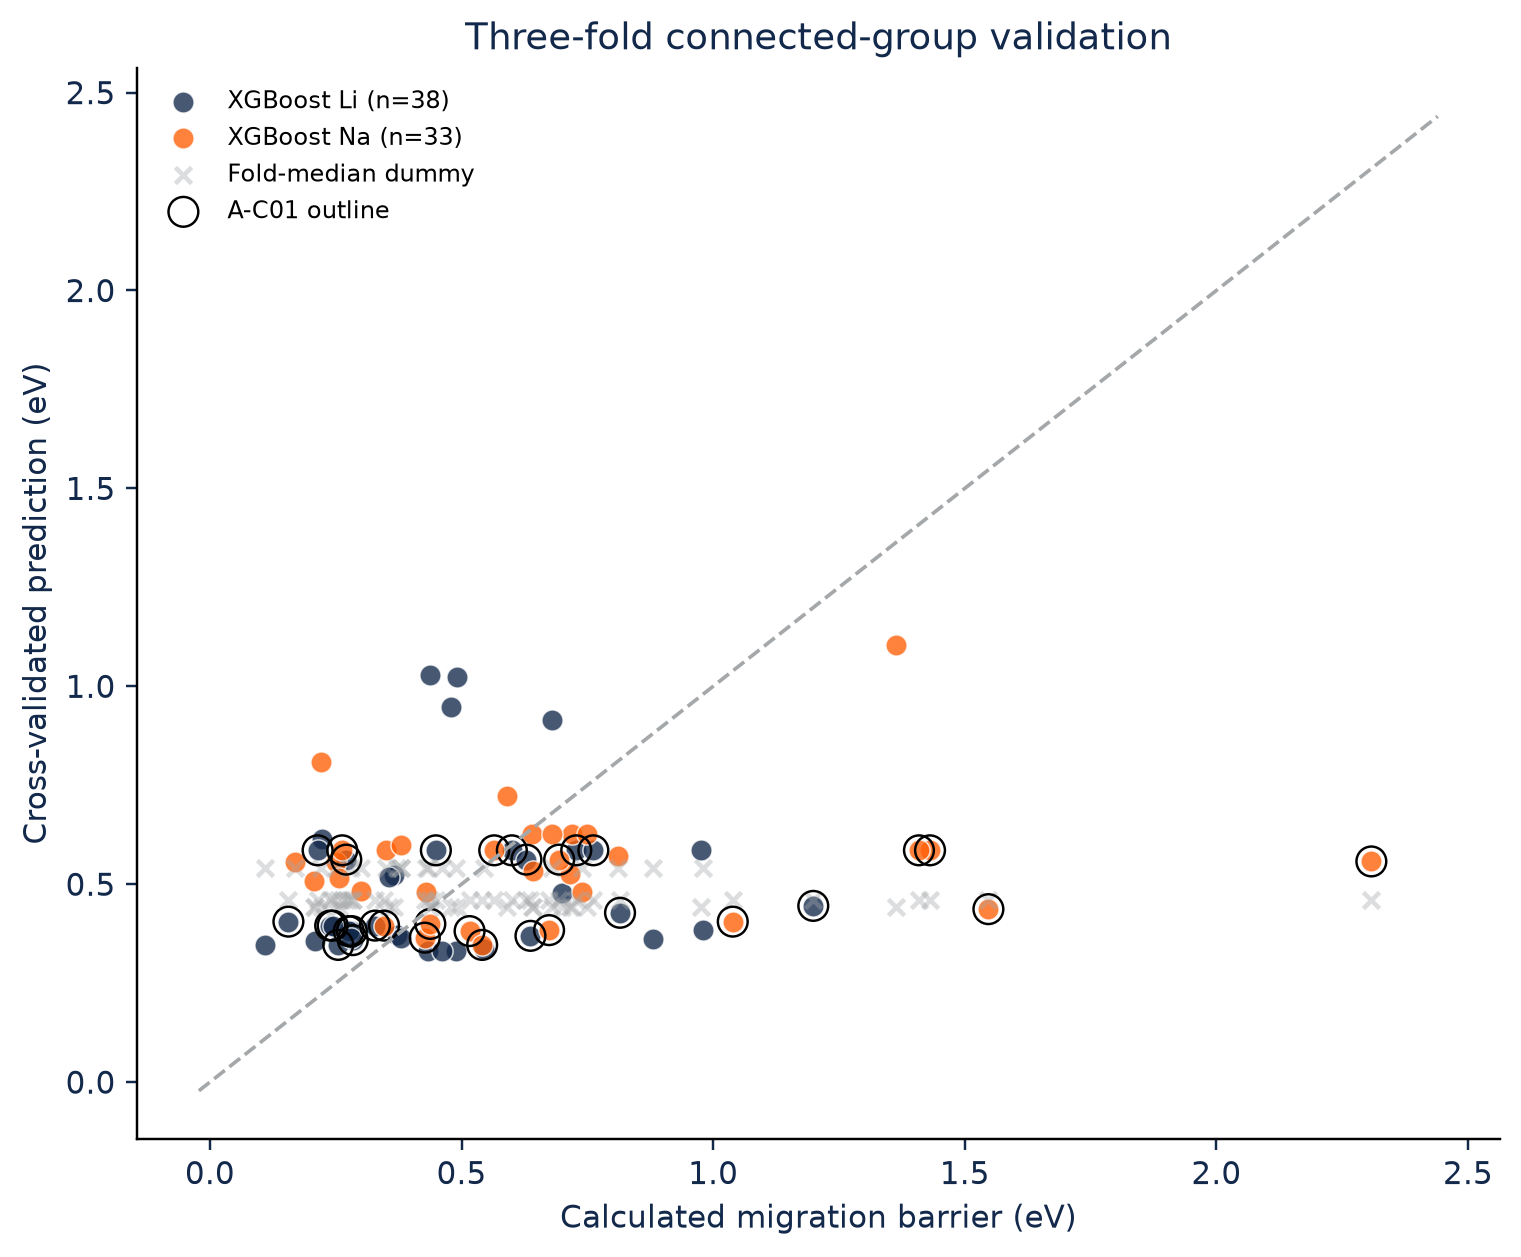

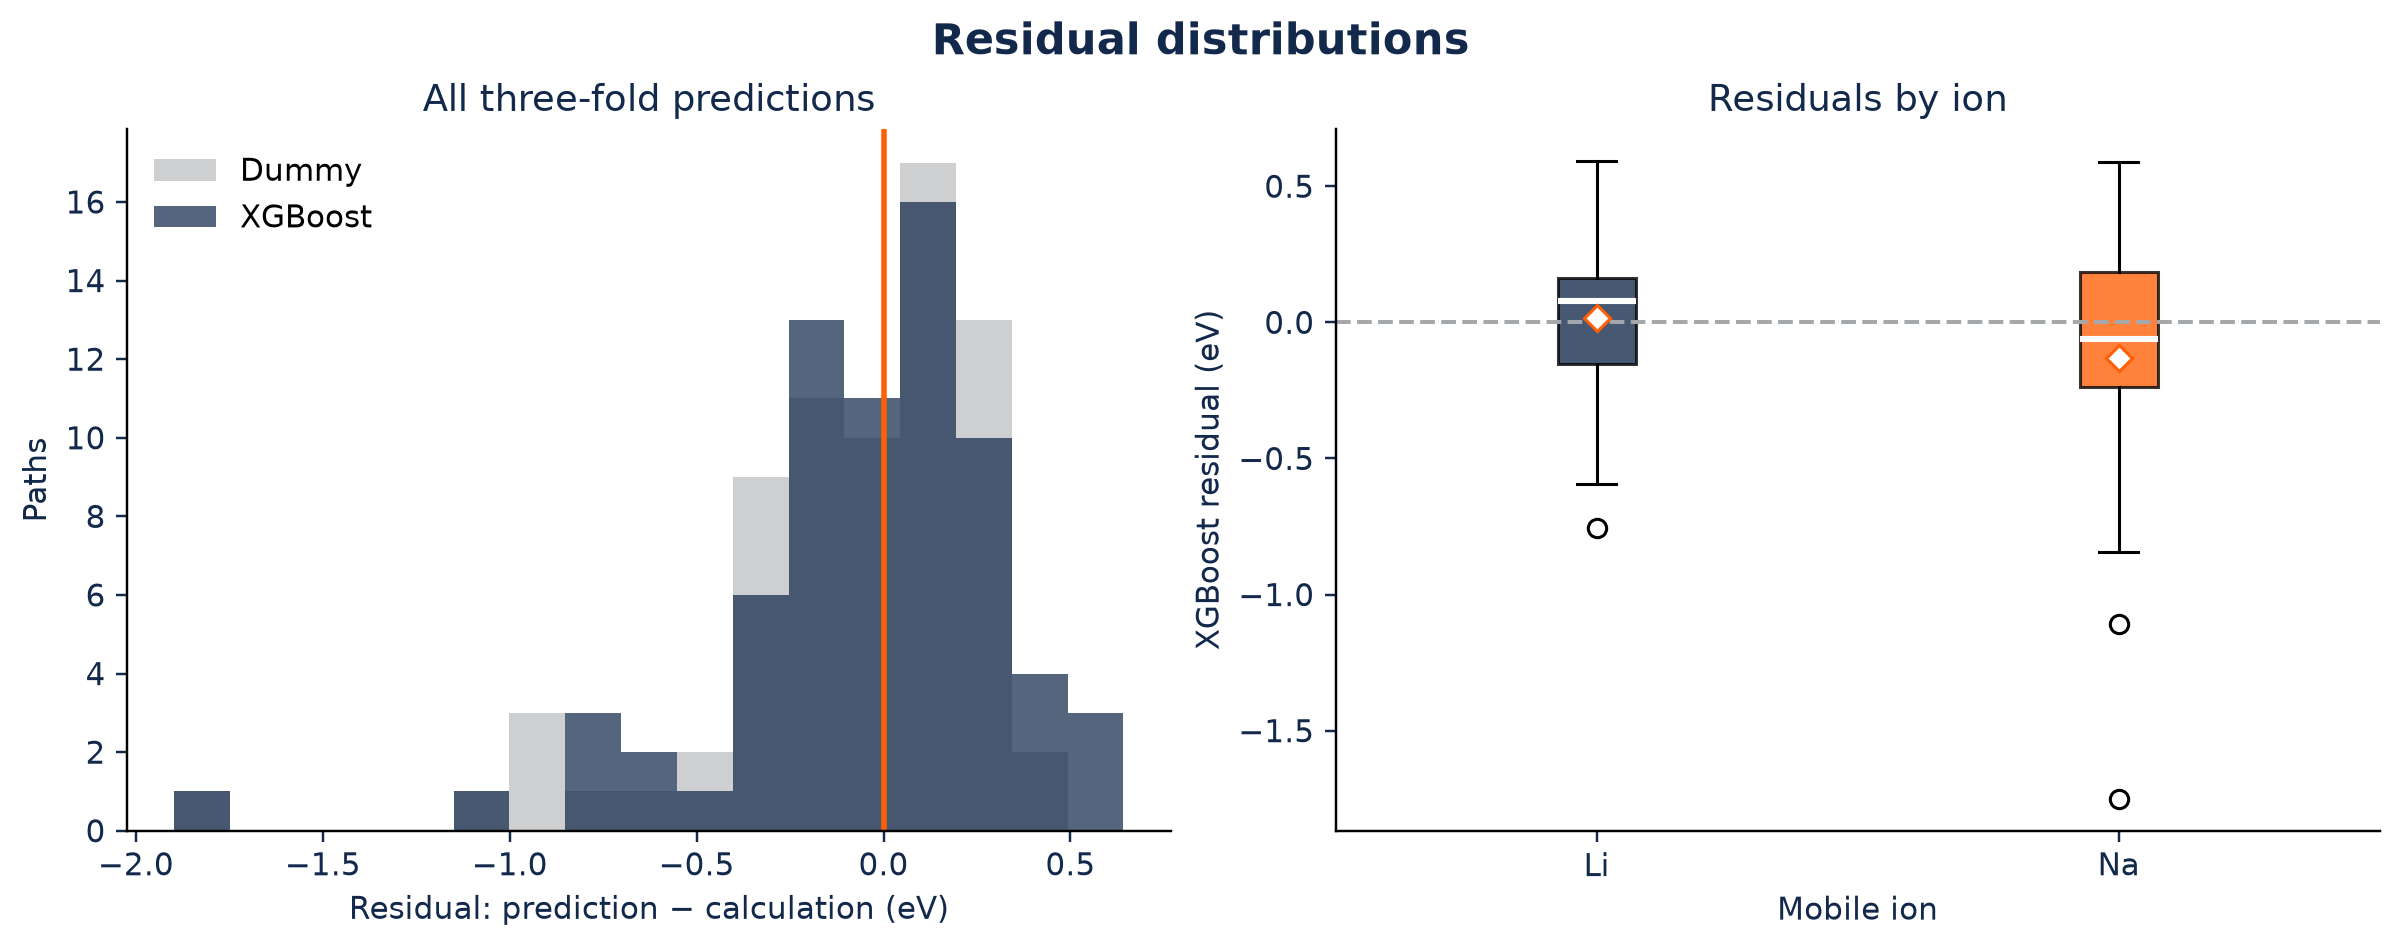

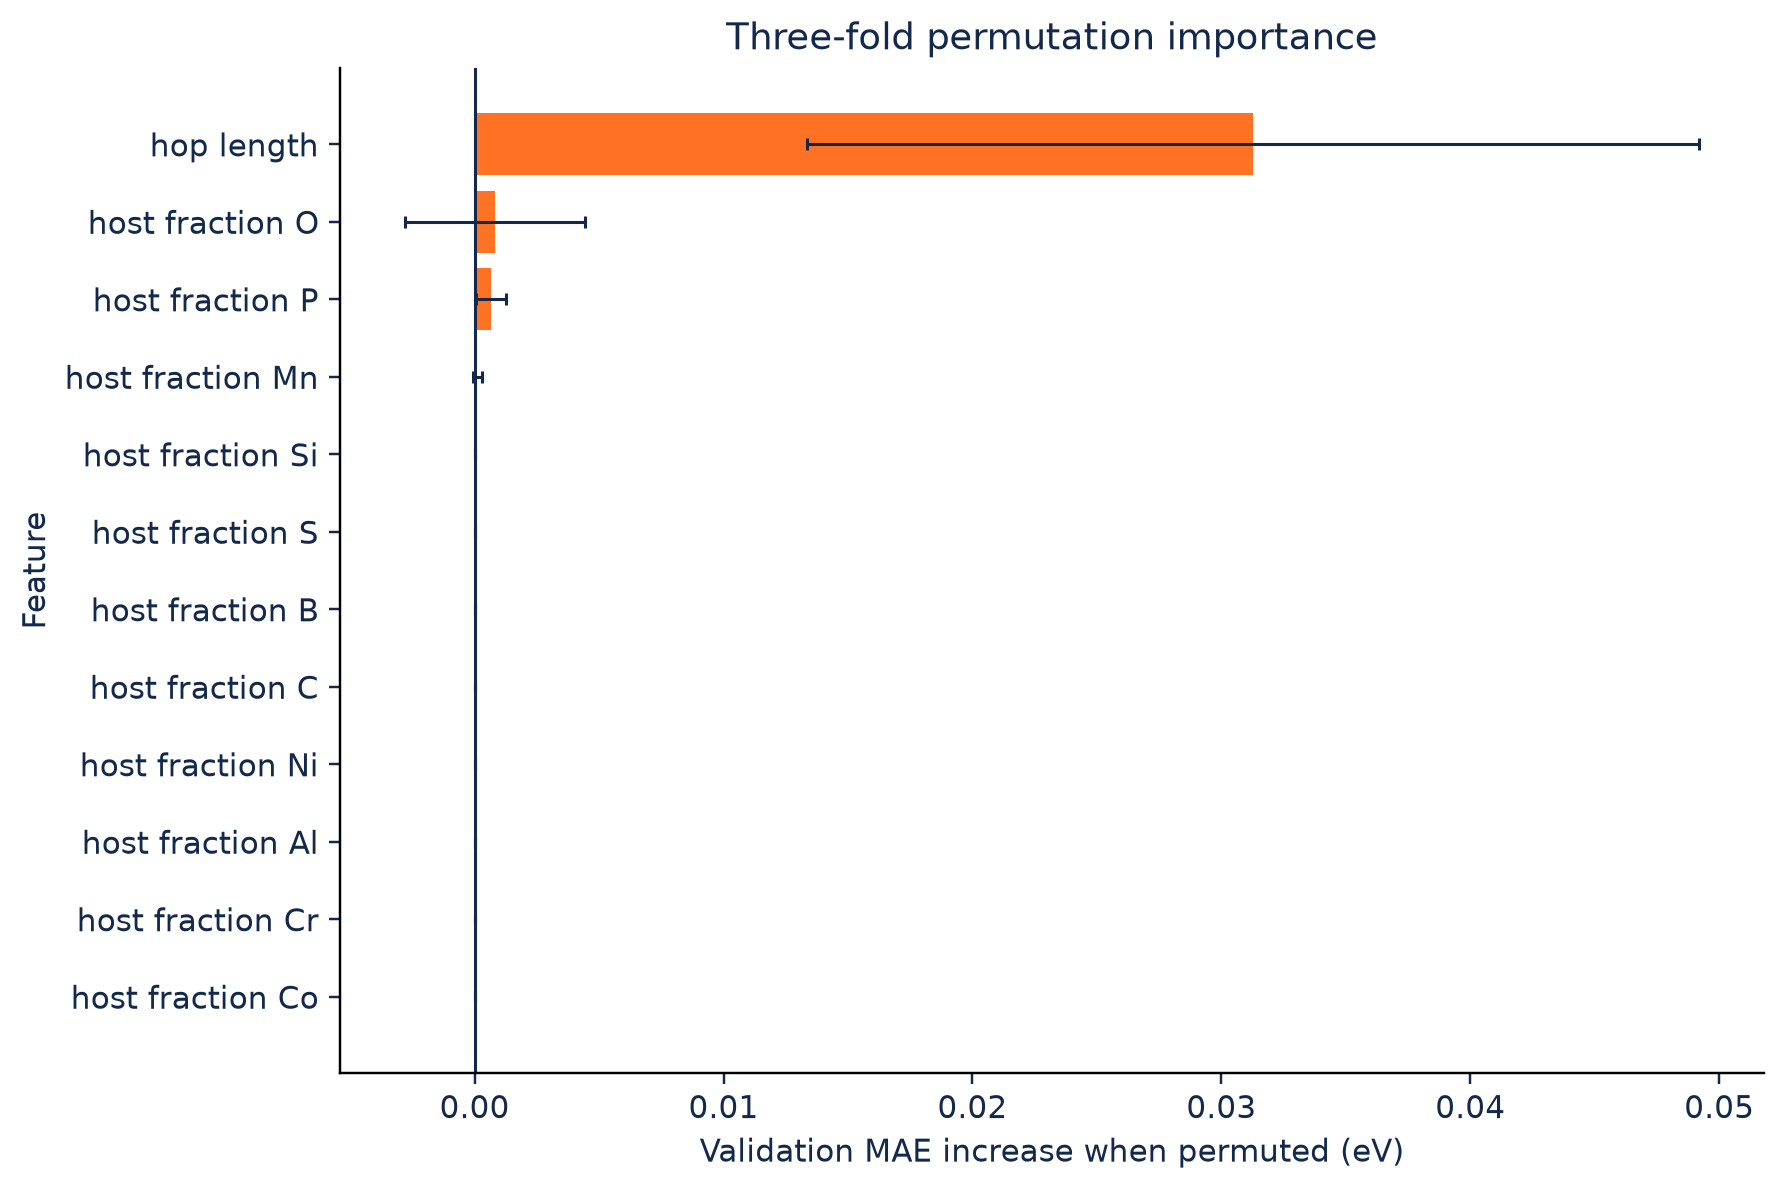

In [8]:
plot_actual_vs_predicted(predictions)
plot_residuals(predictions)
plot_importance(importance)

from IPython.display import Image, display

for figure_name in [
    "01_cross_validated_predicted_vs_actual.png",
    "02_residual_distribution.png",
    "03_permutation_importance.png",
]:
    display(Image(filename=str(FIGURE_DIR / figure_name), width=900))

## 5. Decision

- **Does XGBoost outperform the median baseline?** Not meaningfully. Three-fold MAE improves by only about 0.002 eV (0.8%), while LOGO MAE is slightly worse.
- **Does grouped validation demonstrate predictive ability?** No. Pooled (R^2) is negative for both validation schemes, and predictions contract toward the center rather than following high barriers.
- **Most informative feature:** hop length, with the important warning that permutation importance is not physical causation.
- **Is 71 paths sufficient?** It is sufficient to test the pipeline, but not to support model refinement, dependable generalization to unfamiliar cathode families, or materials selection.
- **Most valuable additional data:** verified cathode barriers from new framework/paper groups; broader high-barrier coverage; balanced Li/Na chemistries; multiple well-defined paths per structure; and consistent phase, state-of-charge, and local pathway geometry metadata.

The dominant A-C01 group supplies 32 of 71 paths. XGBoost improves over the median inside that group but becomes worse when it is removed, so the small aggregate gain is not robust.

### Scientific scope

This model predicts DFT migration barriers **only for already enumerated migration paths**. It does not directly predict experimental ionic conductivity, diffusion coefficients, effective electrode ionic conductivity, or barriers for arbitrary Materials Project candidates without corresponding path information.